# Rosette gradient-echo imaging

A rosette samples k-space along **petals**: the trajectory swings out from the centre to the edge
and back while slowly turning, so one readout passes through `k = 0` again and again,

$$k(t) = k_{max} \sin(\omega_1 t)\, e^{i \omega_2 t}, \qquad k = k_x + i k_y .$$

$\omega_1$ is the fast radial oscillation — one petal lasts $\pi/\omega_1$ — and $\omega_2$ the slow
rotation; $k_{max} = N/(2\,\mathrm{FOV})$ sets the resolution. Noll introduced multishot rosettes
for spectrally selective imaging. The repeated visits are why: a spin off resonance by
$\Delta f$ gains phase $2\pi \Delta f\, t$, so its contributions at successive returns to the
centre arrive with different phases, while signal on resonance arrives in phase every time. Each shot is a slice-selective excitation, one rosette readout in the slice plane, a
spoiler and a fixed TR; the shots differ only in the angle the rosette is rotated by.

`sc.modules.RosetteReadout` is **one readout**: whole petals, starting and ending at rest. This
notebook builds the rest — the excitation, the spoiler, the TR, RF spoiling, the steady-state
dummies and the shot schedule — then writes the file, reads it back, and measures what it
encodes: where the samples are, when the first echo is, and how densely the shots cover k-space.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pypulseq as pp
from scipy.spatial import cKDTree

import seqcraft as sc

opts = pp.Opts(
    max_grad=32, grad_unit='mT/m',
    max_slew=120, slew_unit='T/m/s',
    rf_dead_time=100e-6,
    rf_ringdown_time=30e-6,
    adc_dead_time=10e-6,
    adc_samples_limit=8192,
)
GAMMA = opts.gamma                   # Hz/T, to print gradients in mT/m and T/m/s

FOV_MM, MATRIX, THICKNESS_MM = 256.0, 128, 5.0
PETALS, OMEGA_RATIO, DWELL_S = 13, 7 / 13, 2e-6
SHOTS, FLIP_DEG, TR_S = 16, 15.0, 15e-3

SEQ_DIR = Path('seq')
SEQ_DIR.mkdir(exist_ok=True)
raster = sc.Raster(opts.grad_raster_time)

/opt/homebrew/Caskroom/miniforge/base/envs/seqcraft-dev/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The readout

Thirteen petals at $\omega_2/\omega_1 = 7/13$: narrow petals, each turned a little from the last.
The gradient is $dk/dt$, so its demands follow from the parameters:

$$|g|_{max} = k_{max} \max(\omega_1, \omega_2), \qquad |\dot g|_{max} = k_{max} (\omega_1^2 + \omega_2^2).$$

With no petal duration given, the readout takes the **shortest petal on the gradient raster** that
keeps both within the scanner's limits — applied to the in-plane vector, so every rotation is
legal on every axis — and keeps the raster's departure from the analytic curve within a fixed
budget. The analytic gradient is played piecewise linearly between raster edges, so the slew the
hardware is asked for on each raster is a secant of the curve, never more than its peak.

In [2]:
rosette = sc.modules.RosetteReadout(opts=opts, fov_mm=FOV_MM, matrix=MATRIX, petals=PETALS,
                                    omega_ratio=OMEGA_RATIO, dwell_s=DWELL_S)
w1 = math.pi / rosette.petal_duration_s
w2 = OMEGA_RATIO * w1
k_max, dk = rosette.k_max_per_m, rosette.dk_per_m
played_g, played_s = rosette.limits()

print(f'k_max {k_max:.1f} 1/m = {k_max / dk:.0f} dk, dk = 1/FOV = {dk:.3f} 1/m')
print(f'petal {rosette.petal_duration_s * 1e6:.0f} us: {PETALS} petals take '
      f'{PETALS * rosette.petal_duration_s * 1e3:.2f} ms, the whole block {rosette().duration * 1e3:.3f} ms')
print()
print(f'{"":10}{"analytic":>10}{"played":>10}{"limit":>10}')
print(f'{"|g| mT/m":10}{k_max * max(w1, w2) / GAMMA * 1e3:10.2f}{played_g / GAMMA * 1e3:10.2f}'
      f'{opts.max_grad / GAMMA * 1e3:10.2f}')
print(f'{"slew T/m/s":10}{k_max * (w1**2 + w2**2) / GAMMA:10.2f}{played_s / GAMMA:10.2f}'
      f'{opts.max_slew / GAMMA:10.2f}')
shorter = math.pi / (rosette.petal_duration_s - opts.grad_raster_time)
print(f'one raster shorter, the analytic slew would be '
      f'{k_max * shorter**2 * (1 + OMEGA_RATIO**2) / GAMMA:.2f} T/m/s')
print()
print(f'one ADC event of {rosette.num_samples} samples at {DWELL_S * 1e6:g} us')
print(f'raster departure from the analytic curve at most {rosette.departure_per_m / dk:.4f} dk '
      f'(budget 0.05 dk)')

k_max 250.0 1/m = 64 dk, dk = 1/FOV = 3.906 1/m
petal 790 us: 13 petals take 10.27 ms, the whole block 11.250 ms

            analytic    played     limit
|g| mT/m       23.35     23.35     32.00
slew T/m/s    119.78    119.76    120.00
one raster shorter, the analytic slew would be 122.87 T/m/s

one ADC event of 5140 samples at 2 us
raster departure from the analytic curve at most 0.0200 dk (budget 0.05 dk)


This petal is **slew-limited**: one raster shorter and the analytic slew would pass the limit,
while the gradient stays well below its own. The played slew sits just under the analytic peak,
because a secant across one raster cannot reach the curve's steepest point. The lead-in that
brings the gradient up from rest and the lead-out that returns it, together with a short triangle
cancelling what the core leaves, are designed on the raster directly; the whole block ends at rest
with no net in-plane moment, so no rewinder follows it.

## Where the trajectory crosses the origin

The core passes through `k = 0` at $t_p = p\pi/\omega_1$, `p = 0 … 13` — fourteen crossings
counting both ends. The readout reports each one three ways: the formula's **ideal** instant, the
**closest approach** of the trajectory actually played (the raster moves it slightly), and the
**sample nearest** the ideal instant. Which crossing is called TE is the composition's choice; here
it is the first.

In [3]:
ideal = np.array(rosette.origin_crossing_ideal_s)
closest = np.array(rosette.origin_crossing_closest_s)
residual = np.array(rosette.origin_crossing_residual_per_m)
nearest = np.array(rosette.origin_crossing_samples)
t_report = rosette.sample_times_s()

print(f'{"p":>3}{"ideal / us":>12}{"closest - ideal / ns":>22}{"residual / dk":>15}'
      f'{"sample":>8}{"sample - ideal / ns":>21}')
for p in range(len(ideal)):
    print(f'{p:3d}{ideal[p] * 1e6:12.2f}{(closest[p] - ideal[p]) * 1e9:22.3f}{residual[p] / dk:15.1e}'
          f'{nearest[p]:8d}{(t_report[nearest[p]] - ideal[p]) * 1e9:21.1f}')
core = rosette.core_samples
print()
print(f'samples {core.start} to {core.stop - 1} lie on the core; {core.start} before it, on the '
      f'lead-in, and {rosette.num_samples - core.stop} after it')

  p  ideal / us  closest - ideal / ns  residual / dk  sample  sample - ideal / ns
  0      480.00                -0.000        0.0e+00       0              -1000.0
  1     1270.00               -35.426        8.0e-03     395              -1000.0
  2     2060.00                -8.539        1.8e-02     790              -1000.0
  3     2850.00                33.365        1.2e-02    1185              -1000.0
  4     3640.00                16.586        1.0e-03    1580              -1000.0
  5     4430.00               -29.371        3.9e-03    1975              -1000.0
  6     5220.00               -23.661        1.6e-02    2370              -1000.0
  7     6010.00                23.661        1.6e-02    2765              -1000.0
  8     6800.00                29.371        3.9e-03    3160              -1000.0
  9     7590.00               -16.586        1.0e-03    3555              -1000.0
 10     8380.00               -33.365        1.2e-02    3950              -1000.0
 11     9170.00 

The played trajectory comes within 0.02 `dk` of the origin at every crossing, a few tens of
nanoseconds from the ideal instant. The crossings are on the gradient raster and the samples are
not: at this dwell each crossing falls exactly midway between two samples, and the earlier one is
reported. The samples outside the core are real data, taken while the gradient ramps up and while
it returns to rest; `k_per_m` reports where each of them is.

## One repetition, the steady state and the shot schedule

A repetition is the excitation, the rosette at its shot's angle, a spoiler on the slice axis, and
a delay to TR. RF spoiling advances the transmit phase quadratically by 117° and the receiver
follows it.

The shots must not start until the longitudinal magnetisation has settled. With ideal spoiling,
each TR moves $M_z$ towards its steady state

$$M_{ss} = M_0 \frac{1 - E_1}{1 - \cos\alpha\, E_1}, \qquad E_1 = e^{-TR/T_1},$$

by the factor $q = \cos\alpha\, E_1$, so the number of dummy repetitions follows from how close is
close enough — here 5 % of $M_{ss}$ for grey matter at 3 T.

In [4]:
exc = sc.modules.Excitation(opts=opts, flip_deg=FLIP_DEG, thickness_mm=THICKNESS_MM,
                            duration_s=1e-3)
spoil = sc.modules.spoiler(opts, cycles_per_voxel=4.0, voxel_mm=THICKNESS_MM, axis='z')
start_s = float(raster.ceil(exc().duration))
te_s = start_s + rosette.origin_crossing_ideal_s[0] - exc.time_to_center()

T1_S, TOLERANCE = 1.3, 0.05
e1 = math.exp(-TR_S / T1_S)
q = math.cos(math.radians(FLIP_DEG)) * e1
m_ss = (1 - e1) / (1 - q)
DUMMIES = math.ceil(math.log(TOLERANCE * m_ss / (1 - m_ss)) / math.log(q))

print(f'readout starts {start_s * 1e3:.3f} ms after the excitation block opens')
print(f'TE, RF centre to the first crossing: {te_s * 1e3:.3f} ms')
print(f'steady state {m_ss:.3f} M0, approached by q = {q:.4f} per TR: '
      f'{DUMMIES} dummies, {DUMMIES * TR_S:.2f} s')

readout starts 1.930 ms after the excitation block opens
TE, RF centre to the first crossing: 1.750 ms
steady state 0.254 M0, approached by q = 0.9548 per TR: 89 dummies, 1.33 s


In [5]:
def angles(n):
    """Equal rotations over 2 pi: one per shot."""
    return [2.0 * np.pi * s / n for s in range(n)]


def phase_deg(n, increment=117.0):
    """RF spoiling, quadratic in the repetition index."""
    return 0.5 * increment * n * (n + 1)


def repetition(angle_rad, *, phase, acquire=True):
    """Excite, play the rosette at `angle_rad`, spoil, fill to TR."""
    out = sc.LogicBlock('rosette_tr').add(0.0, exc(phase_deg=phase))
    readout = rosette(angle_rad=angle_rad, acquire=acquire, phase_deg=phase)
    out.add(start_s, readout)
    tail = start_s + readout.duration
    out.add(tail, spoil)
    fill = float(raster.ceil(TR_S - tail - spoil.duration))
    assert fill >= 0.0, 'one repetition does not fit in TR'
    if fill > 1e-9:
        out.add(tail + spoil.duration, pp.make_delay(fill))
    return out


scan = sc.LogicBlock('gre_rosette_2d')
for n in range(DUMMIES):
    scan.add(n * TR_S, repetition(0.0, phase=phase_deg(n), acquire=False))
for s, angle in enumerate(angles(SHOTS)):
    scan.add((DUMMIES + s) * TR_S, repetition(angle, phase=phase_deg(DUMMIES + s)))

print(f'{DUMMIES} dummies and {SHOTS} shots, TR {TR_S * 1e3:g} ms: {scan.duration:.3f} s')

89 dummies and 16 shots, TR 15 ms: 1.575 s


## What the file encodes

The sequence is compiled, written and read back, and the trajectory is computed from the file by
PyPulseq's own reader — not from the readout's report — then compared with that report shot by
shot. A `.seq` file stores each gradient amplitude to six significant digits, which bounds how
closely the two can agree.

In [6]:
seq = sc.compile(scan, opts, name='gre_rosette_2d', definitions={
    'FOV': [FOV_MM / 1e3, FOV_MM / 1e3, THICKNESS_MM / 1e3], 'TE': te_s, 'TR': TR_S,
})
path = SEQ_DIR / 'gre_rosette_2d.seq'
seq.write(str(path))
back = pp.Sequence(system=opts)
back.read(str(path))
k_file, t_file, _, _, t_excitation = back.calculate_kspacePP()[:5]

n_samples = rosette.num_samples
k_file = np.asarray(k_file)[:2].reshape(2, SHOTS, n_samples)
t_file = np.asarray(t_file).reshape(SHOTS, n_samples)
k_error = max(np.max(np.hypot(*(k_file[:, s] - rosette.k_per_m(angle_rad=a))))
              for s, a in enumerate(angles(SHOTS)))
t_error = max(np.max(np.abs(t_file[s] - ((DUMMIES + s) * TR_S + start_s) - t_report))
              for s in range(SHOTS))

print(f'{len(back.block_events)} blocks, {back.duration()[0]:.3f} s, '
      f'{SHOTS * n_samples} samples -> {path}')
print(f'trajectory, file against report, worst shot: {k_error / dk:.1e} dk')
print(f'sample times, file against report:           {t_error * 1e9:.1e} ns')

rf_centres = np.asarray(t_excitation)[DUMMIES:]
first = nearest[0]
print()
print(f'{"shot":>5}{"angle / deg":>13}{"RF centre to first-crossing sample / ms":>41}{"|k| there / dk":>16}')
for s, a in enumerate(angles(SHOTS)):
    print(f'{s:5d}{math.degrees(a):13.1f}{(t_file[s, first] - rf_centres[s]) * 1e3:41.4f}'
          f'{np.hypot(*k_file[:, s, first]) / dk:16.2e}')

525 blocks, 1.575 s, 82240 samples -> seq/gre_rosette_2d.seq
trajectory, file against report, worst shot: 3.0e-05 dk
sample times, file against report:           1.9e-06 ns

 shot  angle / deg  RF centre to first-crossing sample / ms  |k| there / dk
    0          0.0                                   1.7490        2.54e-01
    1         22.5                                   1.7490        2.54e-01
    2         45.0                                   1.7490        2.54e-01
    3         67.5                                   1.7490        2.54e-01
    4         90.0                                   1.7490        2.54e-01
    5        112.5                                   1.7490        2.54e-01
    6        135.0                                   1.7490        2.54e-01
    7        157.5                                   1.7490        2.54e-01
    8        180.0                                   1.7490        2.54e-01
    9        202.5                                   1.7490       

In every shot the sample nearest the first crossing lies 1.749 ms after the RF centre: half a
dwell before the TE computed above, because the crossing falls midway between two samples. It is
a quarter of `dk` from the origin, half the distance the trajectory covers in one dwell where it
moves fastest. RF spoiling changes only phases, so every shot's timing is the same.

## Covering k-space: how many shots

Each shot is the same rosette rotated, so the number of shots and their angles decide how densely
the disk $|k| \le k_{max}$ is sampled. One way to measure it is the **largest hole**: the greatest
distance from any point of the disk to the nearest sample. A Cartesian grid sampled at the Nyquist
rate leaves holes of $\Delta k/\sqrt{2}$ at the centres of its cells, which makes a natural
benchmark — the same edge criterion that sets the number of spokes in a Nyquist-sampled radial
acquisition.

The angles matter as much as their number. This rosette's petal tips all lie on a grid of
directions $\pi/26$ apart, so a rotation that is a whole number of those steps moves petals onto
directions the others already use. $2\pi/13$ is eight steps: thirteen shots reach only 26 distinct
tip directions.

In [7]:
def largest_hole(k, step=dk / 16):
    """Greatest distance from a point of the disk |k| <= k_max to its nearest sample, 1/m."""
    grid = np.arange(-k_max, k_max + step / 2, step)
    gx, gy = np.meshgrid(grid, grid)
    inside = np.hypot(gx, gy) <= k_max
    return float(cKDTree(k.T).query(np.c_[gx[inside], gy[inside]])[0].max())


def rotated(n):
    return np.concatenate([rosette.k_per_m(angle_rad=a) for a in angles(n)], axis=1)


tips = [w2 * (p + 0.5) * rosette.petal_duration_s for p in range(PETALS)]
print(f'benchmark, a Nyquist Cartesian grid: {1 / math.sqrt(2):.3f} dk')
for n in (8, 13, SHOTS):
    directions = {round(((t + a) / (math.pi / 26)) % 52, 6) for t in tips for a in angles(n)}
    print(f'{n:3d} shots, as designed: largest hole {largest_hole(rotated(n)) / dk:.3f} dk, '
          f'{len(directions)} tip directions')
print(f'{SHOTS:3d} shots, read back:   largest hole '
      f'{largest_hole(k_file.reshape(2, -1)) / dk:.3f} dk')
print(f'measured on a grid of dk/16, so the true largest hole is at most '
      f'{1 / (16 * math.sqrt(2)):.3f} dk more')

benchmark, a Nyquist Cartesian grid: 0.707 dk


  8 shots, as designed: largest hole 1.249 dk, 104 tip directions


 13 shots, as designed: largest hole 8.917 dk, 26 tip directions


 16 shots, as designed: largest hole 0.639 dk, 208 tip directions


 16 shots, read back:   largest hole 0.639 dk
measured on a grid of dk/16, so the true largest hole is at most 0.044 dk more


Eight shots leave holes wider than the benchmark. Thirteen are far worse, although they play more
petals than eight, because their rotations land on directions already taken. Sixteen shots meet the benchmark, and the file read back samples k-space exactly as
designed.

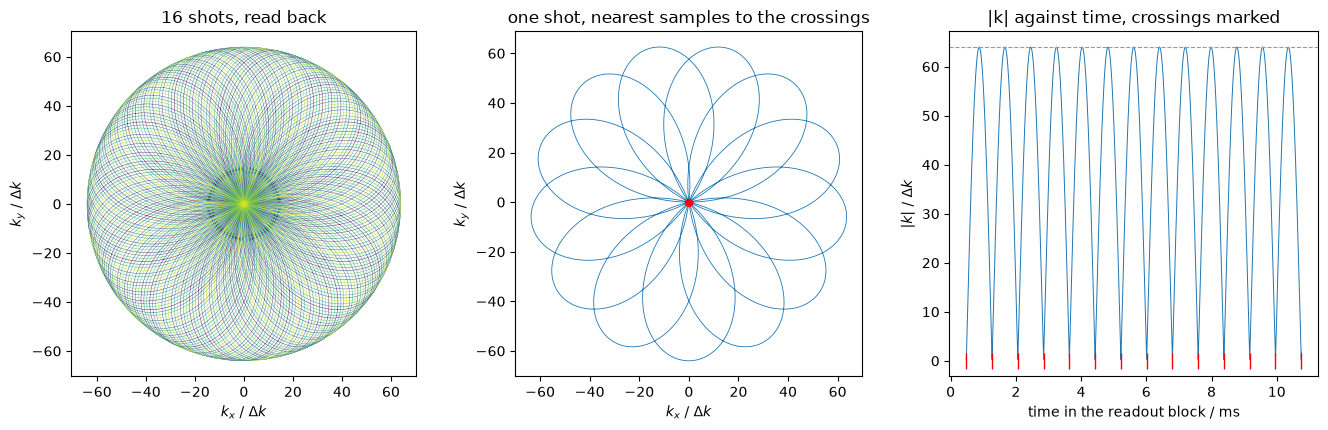

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4))
for s in range(SHOTS):
    axes[0].plot(*k_file[:, s] / dk, lw=0.3, color=plt.cm.viridis(s / SHOTS))
axes[0].set(title=f'{SHOTS} shots, read back', xlabel='$k_x$ / $\\Delta k$',
            ylabel='$k_y$ / $\\Delta k$', aspect='equal')

one = rosette.k_per_m()
axes[1].plot(*one / dk, lw=0.6)
axes[1].plot(*one[:, nearest] / dk, 'r.', ms=7)
axes[1].set(title='one shot, nearest samples to the crossings', xlabel='$k_x$ / $\\Delta k$',
            ylabel='$k_y$ / $\\Delta k$', aspect='equal')

axes[2].plot(t_report * 1e3, np.hypot(*one) / dk, lw=0.7)
axes[2].axhline(k_max / dk, color='0.6', ls='--', lw=0.8)
axes[2].plot(ideal * 1e3, np.zeros_like(ideal), 'r|', ms=12)
axes[2].set(title='|k| against time, crossings marked', xlabel='time in the readout block / ms',
            ylabel='$|k|$ / $\\Delta k$')
fig.tight_layout()

## Limitations

- **No image is formed here.** A rosette samples points other than the origin more than once,
  which makes its density compensation hard to estimate (Bernstein et al., p. 515); this notebook
  builds the acquisition and measures what it samples, and does not simulate or reconstruct it.
- **The largest hole is a sampling benchmark, not an image-quality guarantee.** It says how far any
  point of the disk is from a sample; whether a given reconstruction is adequate at that density
  is a separate question.
- **Off-resonance is not modelled.** The spectral selectivity that motivates rosettes depends on
  the object and on the reconstruction, neither of which is here.
- **The file was read back with PyPulseq, not played.** One 5140-sample ADC event per shot is what
  `adc_samples_limit` is set for; no interpreter or scanner was tested.
- **The dummies are sized for one tissue.** At $T_1$ = 1.3 s the first shot starts within 5 % of
  the steady state; tissue with a longer $T_1$ is still approaching it.
- The slice is not oblique, and the shot angles are equally spaced; neither is a limit of the
  readout.

## Summary

| | |
|---|---|
| **one readout, rotated** | thirteen petals of the analytic rosette, at rest at both ends with no net moment; every shot is the same instance at another angle |
| **slew-limited** | the shortest petal on the raster within the vector limits; the played slew is a secant just under the analytic peak |
| **crossings** | fourteen, each reported as an ideal instant, a closest approach and a nearest sample; TE is the composition's choice of the first |
| **steady state first** | the dummy count follows from $q = \cos\alpha\,e^{-TR/T_1}$ and a tolerance, not from a habit |
| **the file agrees** | trajectory and sample times read back by PyPulseq match the readout's report within the file's six-digit rounding |
| **shots cover k-space** | sixteen meet the Nyquist-Cartesian hole benchmark; thirteen, whose rotations coincide with the petal-tip directions, do not |

## References

- Noll DC. Multishot rosette trajectories for spectrally selective MR imaging. *IEEE Trans Med
  Imaging* 1997;16(4):372–377.
- Bernstein MA, King KF, Zhou XJ. *Handbook of MRI Pulse Sequences.* Elsevier, 2004: §11.2,
  p. 382, the rosette among non-Cartesian trajectories; §13.2, p. 515, density compensation for
  trajectories that sample points more than once; §17.5.1, Eq. 17.98, p. 906, the number of views
  a Nyquist-sampled 2D radial acquisition needs.